In [1]:

import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

url = "https://books.toscrape.com/"

response = requests.get(url, timeout=20)

print("Status Code:", response.status_code)


Status Code: 200


In [2]:

soup = BeautifulSoup(response.text, "html.parser")

books = soup.select("article.product_pod")

print("Total books on first page:", len(books))


Total books on first page: 20


In [3]:

data = []

for book in books:
    title = book.h3.a["title"]

    price = book.select_one(".price_color").get_text(strip=True)
    price = price.replace("£", "").replace("Â", "")

    rating = book.select_one(".star-rating")["class"][1]

    availability = book.select_one(
        ".availability"
    ).get_text(strip=True)

    data.append({
        "Title": title,
        "Price_GBP": float(price),
        "Rating": rating,
        "Availability": availability
    })

df = pd.DataFrame(data)

display(df.head(10))


,Title,Price_GBP,Rating,Availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock
5,The Requiem Red,22.65,One,In stock
6,The Dirty Little Secrets of Getting Your Dream...,33.34,Four,In stock
7,The Coming Woman: A Novel Based on the Life of...,17.93,Three,In stock
8,The Boys in the Boat: Nine Americans and Their...,22.60,Four,In stock
9,The Black Maria,52.15,One,In stock


In [4]:
df.to_csv("books_dataset.csv", index=False)

In [5]:

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Column names:", df.columns.tolist())

Total rows: 20
Total columns: 4
Column names: ['Title', 'Price_GBP', 'Rating', 'Availability']


In [6]:

all_books = []

for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    books = soup.select("article.product_pod")

    for book in books:
        title = book.h3.a["title"]

        price = book.select_one(".price_color").get_text(strip=True)
        price = price.replace("£", "").replace("Â", "")

        rating = book.select_one(".star-rating")["class"][1]

        availability = book.select_one(
            ".availability"
        ).get_text(strip=True)

        all_books.append({
            "Title": title,
            "Price_GBP": float(price),
            "Rating": rating,
            "Availability": availability
        })

    print(f"Page {page} completed")

    time.sleep(0.1)

df = pd.DataFrame(all_books)

print("\nTotal books collected:", len(df))
display(df.head())


Page 1 completed
Page 2 completed
Page 3 completed
Page 4 completed
Page 5 completed
Page 6 completed
Page 7 completed
Page 8 completed
Page 9 completed
Page 10 completed
Page 11 completed
Page 12 completed
Page 13 completed
Page 14 completed
Page 15 completed
Page 16 completed
Page 17 completed
Page 18 completed
Page 19 completed
Page 20 completed
Page 21 completed
Page 22 completed
Page 23 completed
Page 24 completed
Page 25 completed
Page 26 completed
Page 27 completed
Page 28 completed
Page 29 completed
Page 30 completed
Page 31 completed
Page 32 completed
Page 33 completed
Page 34 completed
Page 35 completed
Page 36 completed
Page 37 completed
Page 38 completed
Page 39 completed
Page 40 completed
Page 41 completed
Page 42 completed
Page 43 completed
Page 44 completed
Page 45 completed
Page 46 completed
Page 47 completed
Page 48 completed
Page 49 completed
Page 50 completed

Total books collected: 1000


,Title,Price_GBP,Rating,Availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock


In [7]:

df.to_csv("books_dataset.csv", index=False)

print("CSV saved successfully!")
print("Dataset shape:", df.shape)


CSV saved successfully!
Dataset shape: (1000, 4)


In [8]:

all_books = []

for page in range(1, 51):

    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    books = soup.select("article.product_pod")

    for book in books:
        title = book.h3.a["title"]

        price = book.select_one(".price_color").get_text(strip=True)
        price = price.replace("£", "").replace("Â", "")

        rating = book.select_one(".star-rating")["class"][1]

        availability = book.select_one(
            ".availability"
        ).get_text(strip=True)

        all_books.append({
            "Title": title,
            "Price_GBP": float(price),
            "Rating": rating,
            "Availability": availability
        })

    print(f"Page {page}/50 completed")

    time.sleep(0.1)

df = pd.DataFrame(all_books)

print("Total books collected:", len(df))
display(df.head())


Page 1/50 completed
Page 2/50 completed
Page 3/50 completed
Page 4/50 completed
Page 5/50 completed
Page 6/50 completed
Page 7/50 completed
Page 8/50 completed
Page 9/50 completed
Page 10/50 completed
Page 11/50 completed
Page 12/50 completed
Page 13/50 completed
Page 14/50 completed
Page 15/50 completed
Page 16/50 completed
Page 17/50 completed
Page 18/50 completed
Page 19/50 completed
Page 20/50 completed
Page 21/50 completed
Page 22/50 completed
Page 23/50 completed
Page 24/50 completed
Page 25/50 completed
Page 26/50 completed
Page 27/50 completed
Page 28/50 completed
Page 29/50 completed
Page 30/50 completed
Page 31/50 completed
Page 32/50 completed
Page 33/50 completed
Page 34/50 completed
Page 35/50 completed
Page 36/50 completed
Page 37/50 completed
Page 38/50 completed
Page 39/50 completed
Page 40/50 completed
Page 41/50 completed
Page 42/50 completed
Page 43/50 completed
Page 44/50 completed
Page 45/50 completed
Page 46/50 completed
Page 47/50 completed
Page 48/50 completed
P

,Title,Price_GBP,Rating,Availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock


In [9]:

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRating counts:")
print(df["Rating"].value_counts())

print("\nSummary statistics:")
display(df.describe(include="all"))


Rows and columns: (1000, 4)

Column names:
['Title', 'Price_GBP', 'Rating', 'Availability']

Missing values:
Title           0
Price_GBP       0
Rating          0
Availability    0
dtype: int64

Duplicate rows: 0

Rating counts:
Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

Summary statistics:


,Title,Price_GBP,Rating,Availability
count,1000,1000.00000,1000,1000
unique,999,NaN,5,1
top,The Star-Touched Queen,NaN,One,In stock
freq,2,NaN,226,1000
mean,NaN,35.07035,NaN,NaN
std,NaN,14.44669,NaN,NaN
min,NaN,10.00000,NaN,NaN
25%,NaN,22.10750,NaN,NaN
50%,NaN,35.98000,NaN,NaN
75%,NaN,47.45750,NaN,NaN


In [10]:

df.to_csv("books_dataset.csv", index=False)

print("Dataset saved successfully!")
print("Shape:", df.shape)


Dataset saved successfully!
Shape: (1000, 4)


In [11]:

# 1. Average, minimum and maximum price
print("Average price:", round(df["Price_GBP"].mean(), 2))
print("Minimum price:", df["Price_GBP"].min())
print("Maximum price:", df["Price_GBP"].max())

# 2. Most common rating
print("\nRating counts:")
print(df["Rating"].value_counts())

# 3. Most expensive books
print("\nTop 10 expensive books:")
display(
    df.nlargest(10, "Price_GBP")[
        ["Title", "Price_GBP", "Rating"]
    ]
)

# 4. Cheapest books
print("\nTop 10 cheapest books:")
display(
    df.nsmallest(10, "Price_GBP")[
        ["Title", "Price_GBP", "Rating"]
    ]
)

Average price: 35.07
Minimum price: 10.0
Maximum price: 59.99

Rating counts:
Rating
One      226
Three    203
Five     196
Two      196
Four     179
Name: count, dtype: int64

Top 10 expensive books:


,Title,Price_GBP,Rating
648,The Perfect Play (Play by Play #1),59.99,Three
617,Last One Home (New Beginnings #1),59.98,Three
860,Civilization and Its Discontents,59.95,Two
560,The Barefoot Contessa Cookbook,59.92,Five
366,The Diary of a Young Girl,59.90,Three
657,The Bone Hunters (Lexy Vaughan & Steven Macaul...,59.71,Three
133,Thomas Jefferson and the Tripoli Pirates: The ...,59.64,One
387,Boar Island (Anna Pigeon #19),59.48,Three
393,The Improbability of Love,59.45,One
549,The Man Who Mistook His Wife for a Hat and Oth...,59.45,Four



Top 10 cheapest books:


,Title,Price_GBP,Rating
638,An Abundance of Katherines,10.00,Five
501,The Origin of Species,10.01,Four
716,The Tipping Point: How Little Things Can Make ...,10.02,Two
84,Patience,10.16,Three
302,Greek Mythic History,10.23,Five
558,The Fellowship of the Ring (The Lord of the Ri...,10.27,Two
479,History of Beauty,10.29,Four
242,The Lucifer Effect: Understanding How Good Peo...,10.40,One
434,"NaNo What Now? Finding your editing process, r...",10.41,Four
274,Pet Sematary,10.56,Three


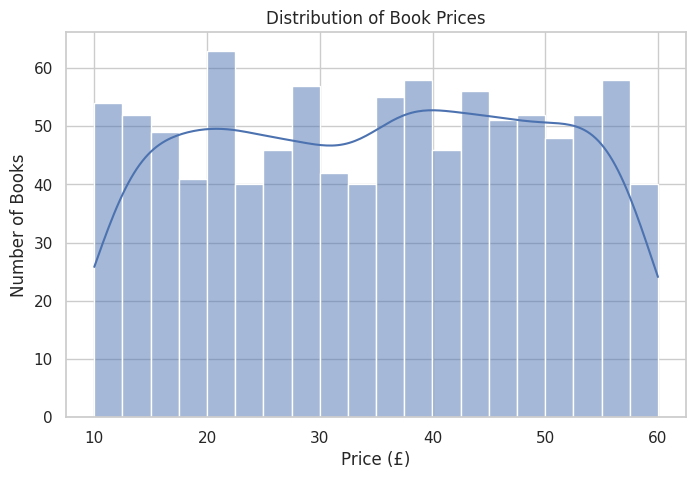

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Price_GBP", bins=20, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()


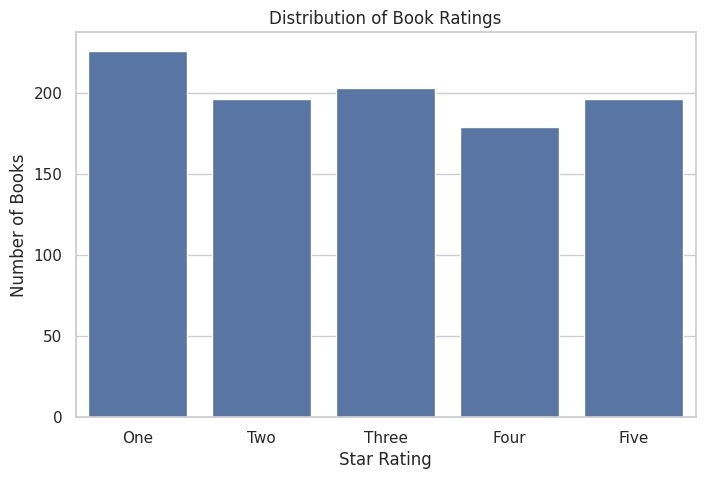

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Rating",
    order=["One", "Two", "Three", "Four", "Five"]
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.show()


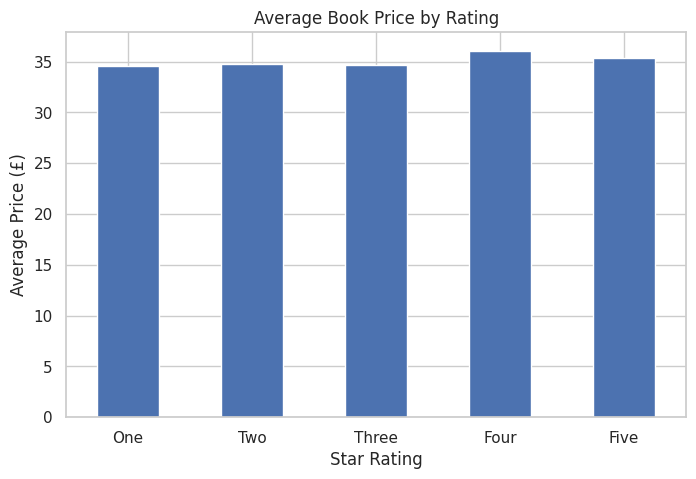

Rating
Five     35.37
Four     36.09
One      34.56
Three    34.69
Two      34.81
Name: Price_GBP, dtype: float64


In [14]:

avg_price = df.groupby("Rating")["Price_GBP"].mean()

plt.figure(figsize=(8, 5))

avg_price.reindex(
    ["One", "Two", "Three", "Four", "Five"]
).plot(kind="bar")

plt.title("Average Book Price by Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=0)
plt.show()

print(avg_price.round(2))


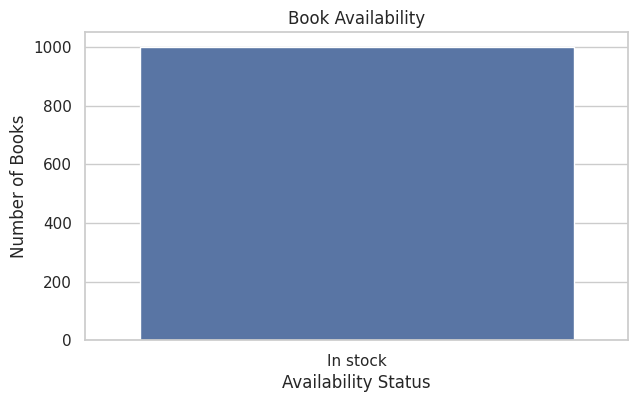

Availability
In stock    1000
Name: count, dtype: int64


In [15]:

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="Availability")

plt.title("Book Availability")
plt.xlabel("Availability Status")
plt.ylabel("Number of Books")
plt.show()

print(df["Availability"].value_counts())


In [16]:

duplicate_titles = df[
    df["Title"].duplicated(keep=False)
].sort_values("Title")

display(duplicate_titles)


,Title,Price_GBP,Rating,Availability
236,The Star-Touched Queen,46.02,Five,In stock
358,The Star-Touched Queen,32.30,Five,In stock


In [17]:

# 1. Overall KPIs
total_books = len(df)
avg_price = df["Price_GBP"].mean()
min_price = df["Price_GBP"].min()
max_price = df["Price_GBP"].max()

print("===== BOOK DATA ANALYSIS =====")
print("Total Books:", total_books)
print("Average Price: £", round(avg_price, 2))
print("Minimum Price: £", min_price)
print("Maximum Price: £", max_price)

# 2. Most common rating
rating_counts = df["Rating"].value_counts()
print("\nMost Common Rating:", rating_counts.idxmax())
print("Books with this rating:", rating_counts.max())

# 3. Rating-wise average price
print("\nAverage Price by Rating:")
print(
    df.groupby("Rating")["Price_GBP"]
      .mean()
      .round(2)
      .reindex(["One", "Two", "Three", "Four", "Five"])
)

# 4. Check repeated titles
print("\nUnique Titles:", df["Title"].nunique())
print("Repeated Title Rows:", df["Title"].duplicated().sum())

===== BOOK DATA ANALYSIS =====
Total Books: 1000
Average Price: £ 35.07
Minimum Price: £ 10.0
Maximum Price: £ 59.99

Most Common Rating: One
Books with this rating: 226

Average Price by Rating:
Rating
One      34.56
Two      34.81
Three    34.69
Four     36.09
Five     35.37
Name: Price_GBP, dtype: float64

Unique Titles: 999
Repeated Title Rows: 1


In [18]:

report = f"""
BOOK DATA ANALYSIS REPORT
=========================

1. Total books analyzed: {len(df)}
2. Average book price: £{df['Price_GBP'].mean():.2f}
3. Minimum book price: £{df['Price_GBP'].min():.2f}
4. Maximum book price: £{df['Price_GBP'].max():.2f}
5. Unique book titles: {df['Title'].nunique()}
6. Missing values: {df.isnull().sum().sum()}
7. Duplicate rows: {df.duplicated().sum()}

Rating Distribution:
{df['Rating'].value_counts().to_string()}

Average Price by Rating:
{df.groupby('Rating')['Price_GBP'].mean().round(2).to_string()}
"""

print(report)

with open("analysis_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("\nReport saved as analysis_report.txt")



BOOK DATA ANALYSIS REPORT

1. Total books analyzed: 1000
2. Average book price: £35.07
3. Minimum book price: £10.00
4. Maximum book price: £59.99
5. Unique book titles: 999
6. Missing values: 0
7. Duplicate rows: 0

Rating Distribution:
Rating
One      226
Three    203
Five     196
Two      196
Four     179

Average Price by Rating:
Rating
Five     35.37
Four     36.09
One      34.56
Three    34.69
Two      34.81


Report saved as analysis_report.txt
